# 🧪 06 - Visualization Lab: The Penguin Report, in Pictures

In the Module 07 lab you described the Palmer Penguins with **numbers**: a data dictionary, summary tables, outliers within species, and a Simpson's paradox in the bill measurements. Now the research team wants a **visual report**: a small set of figures that tells the same story to someone who'll never read a table.

You'll build it with everything from notebooks 01–05, check each figure against your Module 07 numbers, and save a finished figure set.

## ✅ Learning Goals
- Turn a numeric finding into the chart that shows it best
- Use one consistent, colorblind-safe palette and category order across a whole report
- Build single charts, small multiples, and a multi-panel summary figure
- Write titles that state findings, and check every chart against the numbers
- Export a complete, labeled figure set

```text
Load & clean (Module 07 lab) → Set report style → Distributions (03)
     → Group comparisons (03, 04) → Composition (02) → Relationships (04)
     → The paradox (04) → Summary figure (01) → Export
```

## 0. Setup
Everything this lab saves goes into **`06-OutputFiles`**. Upload that folder along with this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path('06-OutputFiles')
OUT.mkdir(exist_ok=True)

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Same cleaning as the Module 07 lab
penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS).copy()
penguins['sex'] = penguins['sex'].str.title()
print(penguins.shape)

(342, 7)


## 1. Set the Report Style Once
A report looks like **one** report when every chart uses the same theme, the same category order, and the same color for the same species (notebook 05). Define them once, at the top, and use them everywhere:

In [2]:
sns.set_theme(style='whitegrid', context='notebook')

SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
SPECIES_COLORS = dict(zip(SPECIES, sns.color_palette('colorblind', 3)))
SEX_COLORS = {'Female': '#999999', 'Male': '#333333'}

LABELS = {
    'bill_length_mm': 'Bill length (mm)',
    'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)',
    'body_mass_g': 'Body mass (g)',
}


def finish(ax, title, subtitle=None):
    """Apply the report's title style to an ax (notebook 05)."""
    ax.set_title(title, loc='left', fontweight='bold', pad=22 if subtitle else 6)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color='gray')
    ax.spines[['top', 'right']].set_visible(False)

`finish()` is notebook 01's "functions that draw on an `ax`" idea: every chart gets the same title style with one line.

## 2. Figure 1: Two Groups Hiding in One Distribution
**Module 07 finding:** body mass is roughly symmetric overall (skew ≈ 0.47), and Gentoos are about 1,350 g heavier than the other two species.

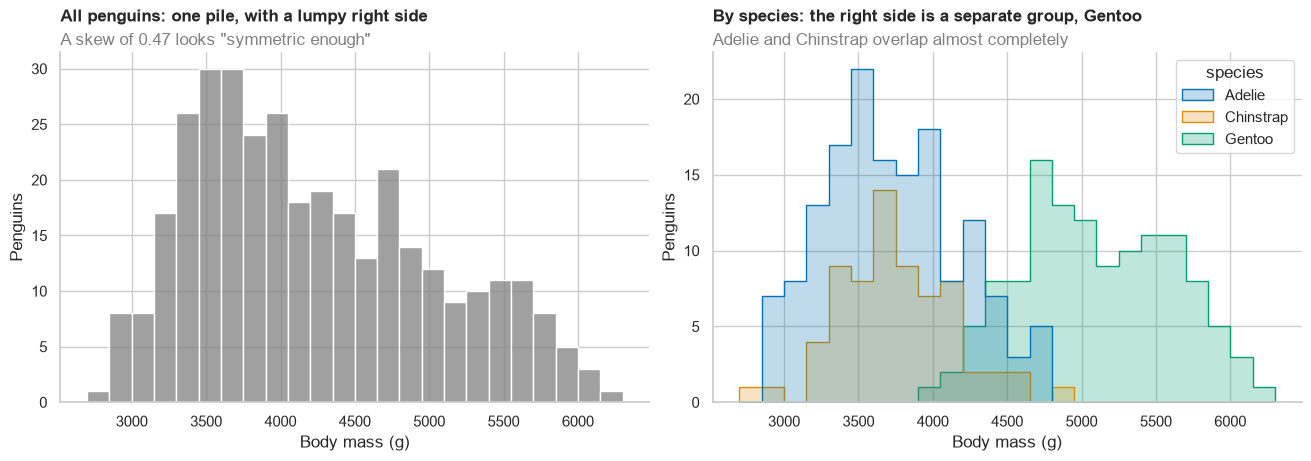

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, layout='constrained')

sns.histplot(data=penguins, x='body_mass_g', binwidth=150, color='gray', ax=axes[0])
finish(axes[0], 'All penguins: one pile, with a lumpy right side', 'A skew of 0.47 looks "symmetric enough"')

sns.histplot(data=penguins, x='body_mass_g', hue='species', hue_order=SPECIES,
             palette=SPECIES_COLORS, binwidth=150, element='step', ax=axes[1])
finish(axes[1], 'By species: the right side is a separate group, Gentoo', 'Adelie and Chinstrap overlap almost completely')

for ax in axes:
    ax.set(xlabel=LABELS['body_mass_g'], ylabel='Penguins')

fig.savefig(OUT / 'fig1_body_mass_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

✅ **Check against the numbers:** the Gentoo group should center near the Module 07 Gentoo mean (about 5,076 g), and the Adelie/Chinstrap humps near 3,700 g. Do they? **Answer:** Yes, they do.

## 3. Figure 2: Species and Sex
**Module 07 finding:** within every species, males are heavier (by about 400–800 g).

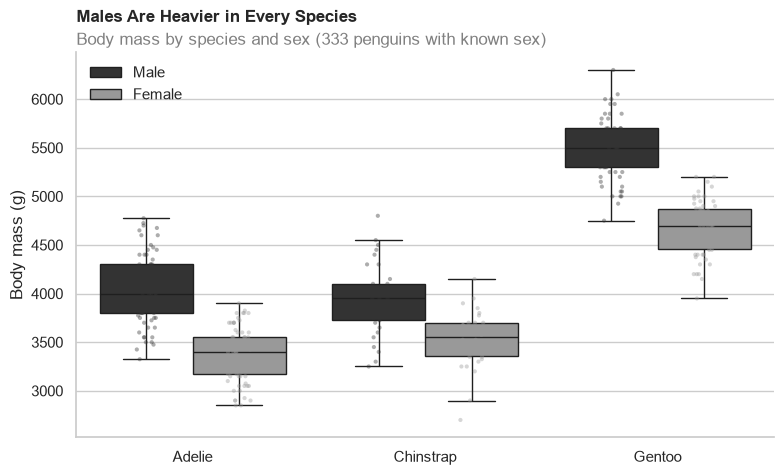

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
            order=SPECIES, palette=SEX_COLORS, showfliers=False, ax=ax)
sns.stripplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
              order=SPECIES, palette=SEX_COLORS, dodge=True, alpha=0.4, size=3,
              legend=False, ax=ax)
ax.set(xlabel='', ylabel=LABELS['body_mass_g'])
ax.legend(title='', frameon=False, loc='upper left')
finish(ax, 'Males Are Heavier in Every Species',
       f'Body mass by species and sex ({penguins["sex"].notna().sum()} penguins with known sex)')

fig.savefig(OUT / 'fig2_mass_by_species_sex.png', dpi=150, bbox_inches='tight')
plt.show()

The subtitle reports the sample size **after** dropping unknown sex, so the reader knows 9 penguins aren't in this chart (Module 07: always say what a summary is based on).

## 4. Figure 3: Where Each Species Lives
**Module 07 finding:** island and species are tangled together. Chinstraps were only measured on Dream, and Gentoos only on Biscoe.

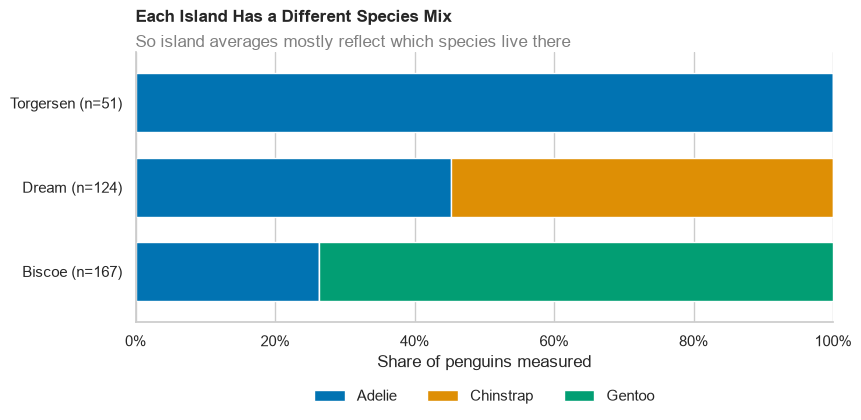

In [5]:
mix = pd.crosstab(penguins['island'], penguins['species'], normalize='index')[SPECIES]
counts = penguins['island'].value_counts()

fig, ax = plt.subplots(figsize=(9, 3.5))
mix.plot.barh(stacked=True, color=[SPECIES_COLORS[s] for s in SPECIES], width=0.7, ax=ax)
ax.set_yticks(range(len(mix)), [f'{island} (n={counts[island]})' for island in mix.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set(xlabel='Share of penguins measured', ylabel='')
ax.legend(title='', frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
finish(ax, 'Each Island Has a Different Species Mix',
       'So island averages mostly reflect which species live there')

fig.savefig(OUT / 'fig3_species_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Figure 4: How the Measurements Relate
**Module 07 finding:** flipper length and body mass are very strongly correlated (r ≈ 0.87).

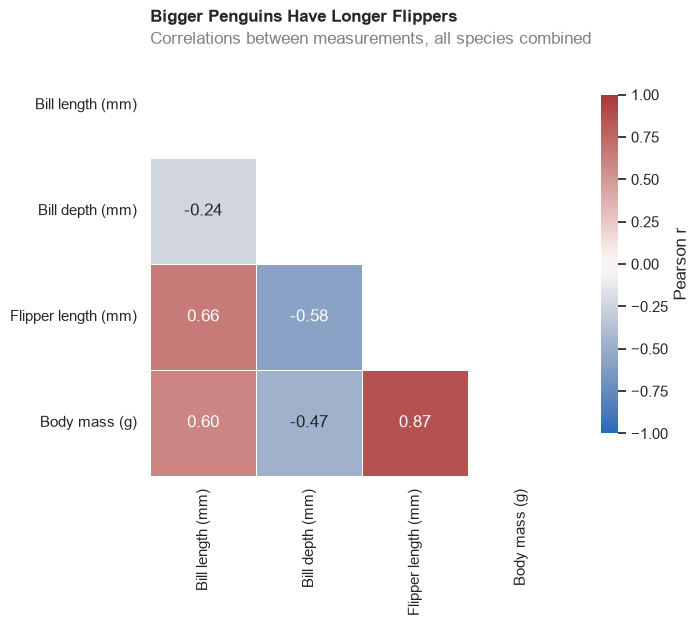

In [6]:
corr = penguins[MEASUREMENTS].rename(columns=LABELS).corr()
mask = np.triu(np.ones(corr.shape, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson r', 'shrink': 0.8}, ax=ax)
finish(ax, 'Bigger Penguins Have Longer Flippers', 'Correlations between measurements, all species combined')
ax.spines[['left', 'bottom']].set_visible(False)
ax.grid(False)        # the whitegrid theme would draw lines through the masked cells

fig.savefig(OUT / 'fig4_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Notice the subtitle: **all species combined.** You know from Module 07 that one of these numbers changes sign within species. That's the next figure, and it's yours to build.

---
## 🛠️ Your Figures
Sections 2–5 were worked examples. Sections 6 and 7 are yours. Use `SPECIES_COLORS`, `SPECIES`, `LABELS`, and `finish()` so they match the rest of the report.

## 6. Figure 5: The Paradox
Build a two-panel figure (`sharex=True, sharey=True`) of bill length vs. bill depth:
- **Left:** all penguins in gray, with one `regplot` trend line and the overall r in the subtitle.
- **Right:** colored by species, with one `regplot` line per species and each species' r in the legend.
- Titles that **state** the finding (for example, "Combined, Longer Bills Look Shallower" / "Within Every Species, Longer Bills Are Deeper").
- Save as `OUT / 'fig5_bill_paradox.png'`.

(Notebook 04 section 3 is your model, but use this report's style.)

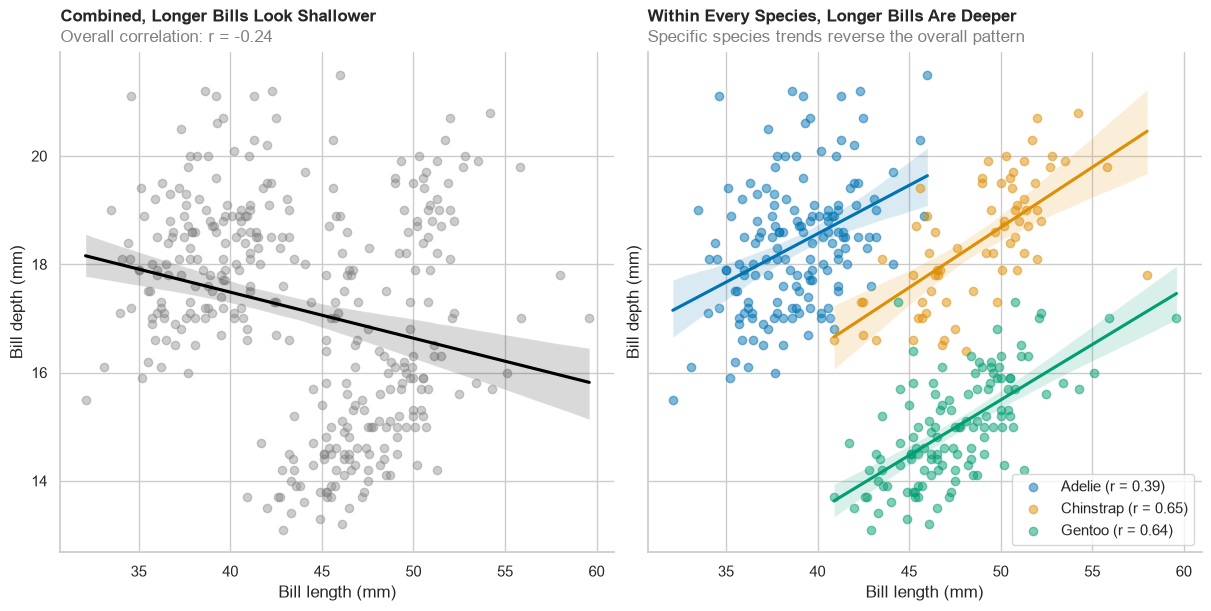

In [7]:
# Your Figure 5 here
# Correlations
r_all = penguins['bill_length_mm'].corr(penguins['bill_depth_mm'])

fig, axes = plt.subplots(1, 2, figsize=(12, 6), sharex=True, sharey=True, layout='constrained')

# Left: Overall relationship
sns.regplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', ax=axes[0],
            scatter_kws={'alpha': 0.4, 'color': 'gray'}, line_kws={'color': 'black'}
)

finish(axes[0], 'Combined, Longer Bills Look Shallower',
       subtitle=f'Overall correlation: r = {r_all:.2f}'
)
axes[0].set(xlabel=LABELS['bill_length_mm'], ylabel=(LABELS['bill_depth_mm']))

# Right: By species
for species, group in penguins.groupby('species'):
    r = group['bill_length_mm'].corr(group['bill_depth_mm'])
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', ax=axes[1],
                color=SPECIES_COLORS[species], scatter_kws={'alpha': 0.5}, label=f'{species} (r = {r:.2f})')
finish(
    axes[1], 'Within Every Species, Longer Bills Are Deeper',
    subtitle='Specific species trends reverse the overall pattern'
)
axes[1].set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])
axes[1].legend()

plt.savefig(OUT / 'fig5_bill_paradox.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()


## 7. Figure 6: The One-Page Summary
Build a single summary figure with `plt.subplot_mosaic()` (notebook 01 Challenge). The skeleton below creates the layout. Fill in each panel:
- `'dist'`: body mass by species (KDE or step histogram)
- `'paradox'`: the species-colored bill scatter from Figure 5
- `'flipper'`: flipper length vs. body mass, colored by species
- `'sex'`: mean body mass by species and sex (`barplot` or `pointplot`)

Give the figure a `suptitle` with the single most important finding, and save it as `OUT / 'fig6_summary.png'`.

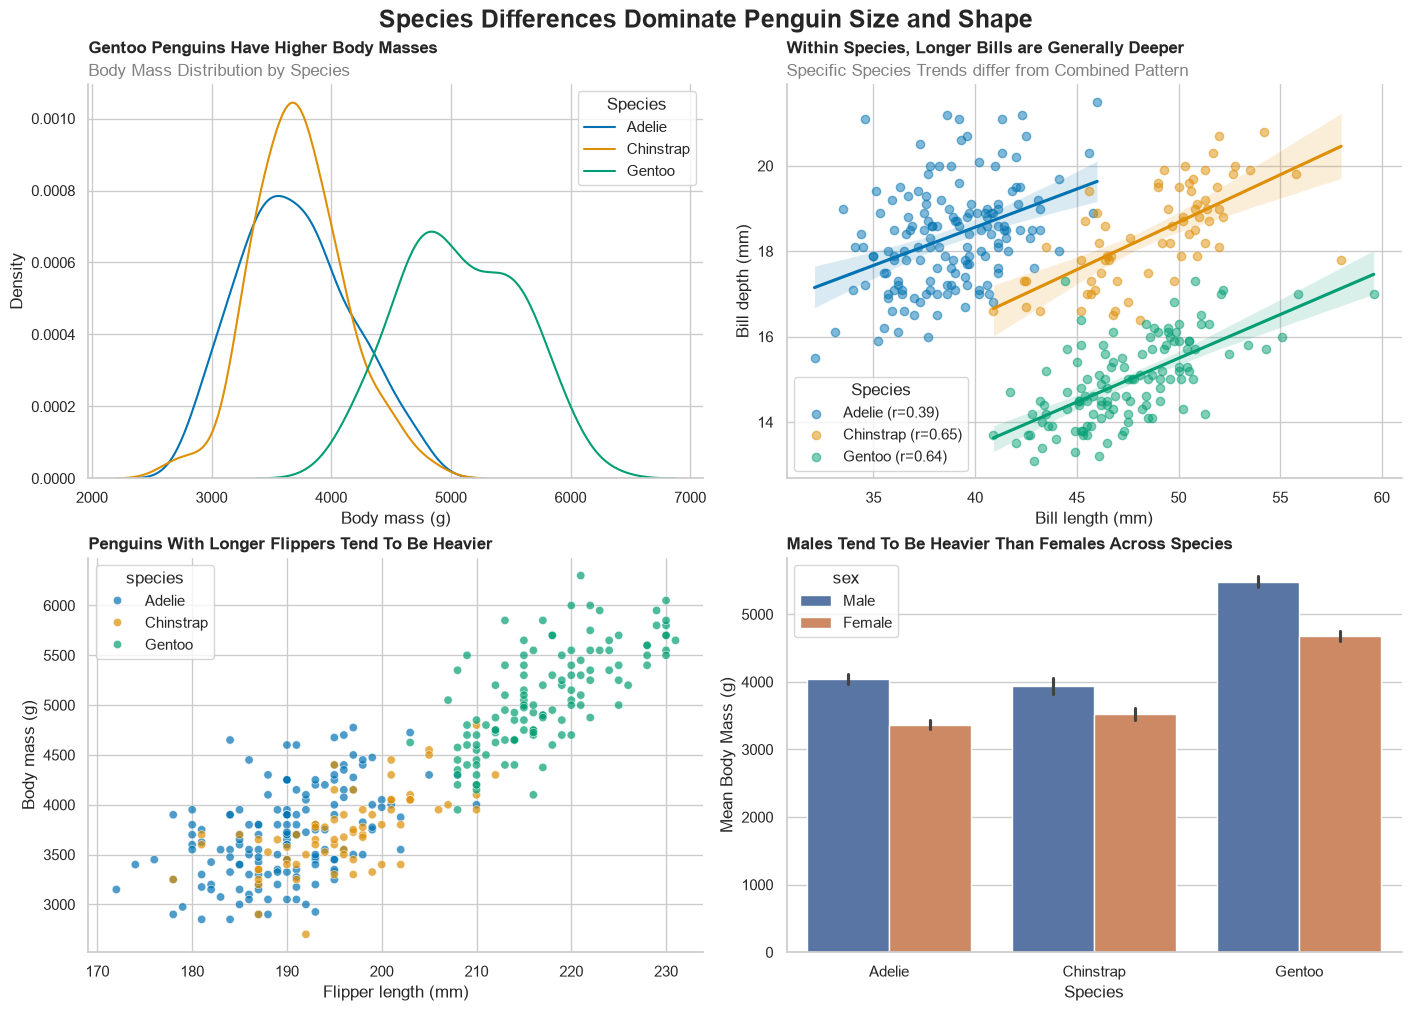

In [8]:
fig, axd = plt.subplot_mosaic(
    [['dist', 'paradox'],
     ['flipper', 'sex']],
    figsize=(14, 10), layout='constrained',
)

# TODO: draw on axd['dist'], axd['paradox'], axd['flipper'], and axd['sex']
# dist: Body mass distribution by species
for species in SPECIES:
    sns.kdeplot(data=penguins[penguins['species'] == species], x='body_mass_g',
                color=SPECIES_COLORS[species], label=species, ax=axd['dist'])

finish(axd['dist'], 'Gentoo Penguins Have Higher Body Masses',
       subtitle='Body Mass Distribution by Species')
axd['dist'].set(xlabel=LABELS['body_mass_g'], ylabel='Density')
axd['dist'].legend(title='Species')

# paradox: Bill length vs. Bill Depth
for species, group in penguins.groupby('species'):
    r = group['bill_length_mm'].corr(group['bill_depth_mm'])
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', color=SPECIES_COLORS[species],
                scatter_kws={'alpha': 0.5}, label=f'{species} (r={r:.2f})', ax=axd['paradox'])
    
finish(axd['paradox'], 'Within Species, Longer Bills are Generally Deeper',
       subtitle='Specific Species Trends differ from Combined Pattern')
axd['paradox'].set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])
axd['paradox'].legend(title='Species')

# flipper: Flipper Length vs. Body Mass
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g',
                hue='species', palette=SPECIES_COLORS, alpha=0.7, ax=axd['flipper'])

finish(axd['flipper'], 'Penguins With Longer Flippers Tend To Be Heavier')
axd['flipper'].set(xlabel=LABELS['flipper_length_mm'], ylabel=LABELS['body_mass_g'])

# sex: Mean Body Mass by Species and Sex
sns.barplot(data=penguins, x='species', y='body_mass_g', hue='sex', ax=axd['sex'])

finish(axd['sex'], 'Males Tend To Be Heavier Than Females Across Species')
axd['sex'].set(xlabel='Species', ylabel='Mean Body Mass (g)')

# TODO: fig.suptitle(...)
fig.suptitle('Species Differences Dominate Penguin Size and Shape', fontsize=18, fontweight='bold')

# TODO: fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')
fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')

plt.show()

## ❓ Lab Questions
Answer each in the Markdown cell below:
1. Figure 1: why did a skew of 0.47 (Module 07) fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?
2. Figure 2: why does the chart use `showfliers=False` on the box plot? What would go wrong without it?
3. Figure 3: why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding `n=` to the labels fix?
4. Figure 5: explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers.
5. Which was easier to **find** the paradox with: the Module 07 tables or the Module 08 chart? Which is better as **evidence**? Why might you want both?
6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?

**Answers:**
1. The skew of 0.47 failed to warn me that the two groups were mixed together because it summarizes the entire distribution with a single number, hiding details. The histogram plot reveals this by showing the different groups, though it can not show a statistic like *exact* outliers.
2. The chart uses `showfliers=False` on the box plot because the strip plot already displays individual observations. Without it, outliers would clutter the chart and distract from the important data.
3. A 100% stacked bar is better choice here as it more clearly shows the species composition of each island. Adding `n=` to the labels fixed the issue of hidden sample sizes.
4. If you look only at the left panel, it would appear that penguins with longer bills tend to have shallower bills due to the downward slope. However, if you look at the right panel, you'll see that the trend slopes upward when the penguins are separated by species. Longer bills are associated with deeper bills inside each species, but combining the species data leads to misleading results, thus the paradox.
5. It was easier to find the paradox with Module 08's charts compared to Module 07's tables. However, Module 07's tables work better as numeric evidence. Showing both is ideal, as the charts clearly show the patterns, while the tables verify those patterns with numeric data.
6. Following **Figure 1**:
    - Question **Valid**: The figure answers a clear question: What does the body mass distribution of all penguins look like, and does separating by species reveal hidden structure?
    - Type **Valid**: A histogram fits the distribution
    - Title **Valid**: both titles state the findings
    - Labels **Fix Needed**: Labels are present, but sample size is missing.
    - Scale **Valid**: Bars start at zero and panels share x-axis.
    - Order **Valid**: Uses predefined species order
    - Color **Valid**: Uses predefined species color
    - Clutter **Valid**: Uses *finish()*, which produces clean output
    - Honesty **Valid**: Chart clearly shows the underlying data structure
    - ***Labels** had to be fixed last.*

## 🏋️ Practice

### Practice 1 — Flipper Length by Species (easy)
Make a violin plot of `flipper_length_mm` by species, with `order=SPECIES` and `palette=SPECIES_COLORS`. Write a title that states the finding, using `finish()`.

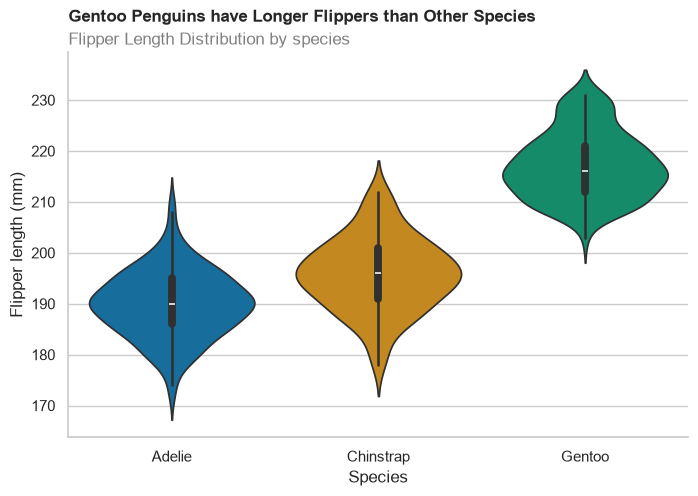

In [9]:
# Your code here
fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(data=penguins, x='species', y='flipper_length_mm', order=SPECIES,
               hue='species', palette=SPECIES_COLORS, legend=False, ax=ax)

ax.set(xlabel='Species', ylabel=LABELS['flipper_length_mm'])

finish(ax, 'Gentoo Penguins have Longer Flippers than Other Species',
       subtitle='Flipper Length Distribution by species')

### Practice 2 — Small Multiples (medium)
Use `sns.displot()` to draw `bill_depth_mm` with `col='species'` and `hue='sex'`, using the report's colors and order. Save it as `OUT / 'practice_bill_depth_grid.png'`.

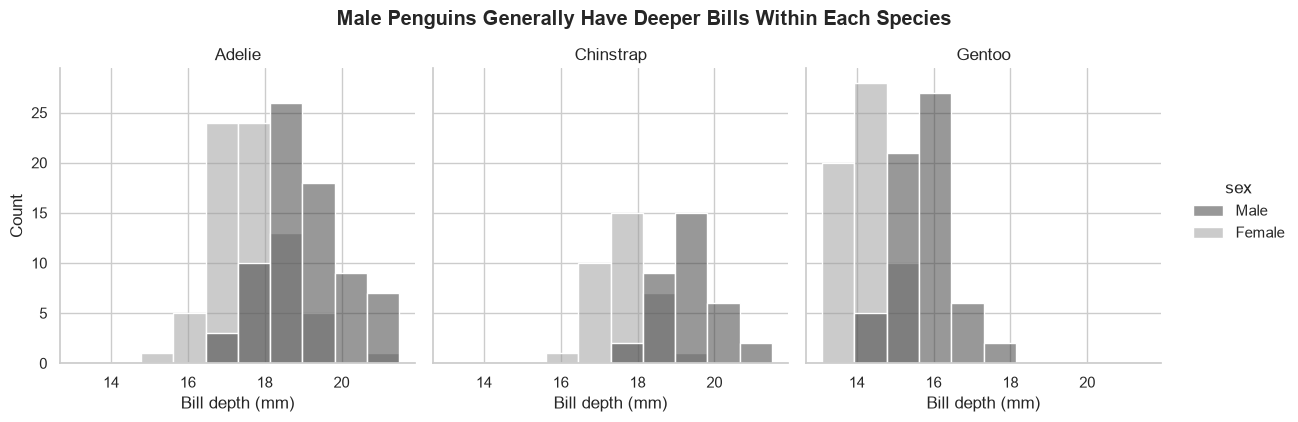

In [10]:
# Your code here
g = sns.displot(data=penguins.dropna(subset=['sex']), x='bill_depth_mm', col='species', col_order=SPECIES,
                hue='sex', palette=SEX_COLORS, height=4, aspect=1)

g.set_axis_labels(LABELS['bill_depth_mm'], 'Count')
g.set_titles('{col_name}')
g.figure.suptitle('Male Penguins Generally Have Deeper Bills Within Each Species', y=1.05, fontweight='bold')
g.figure.savefig(OUT / 'practice_bill_depth_grid.png', dpi=150, bbox_inches='tight')
plt.show()

### Practice 3 — A Fair Island Comparison (harder)
Module 07's lab Practice 2 compared Adelie body mass across islands (the only species on all three). Make the chart version: a box + strip plot of Adelie `body_mass_g` by island, with sample sizes in the tick labels. Does the chart agree with your numbers?

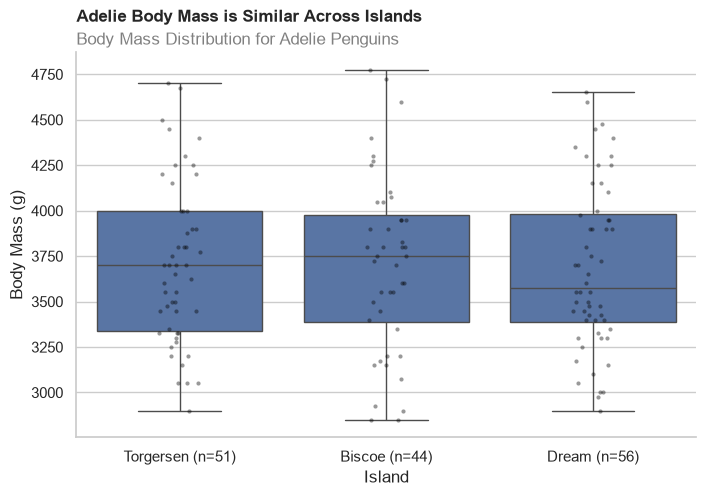

In [11]:
# Your code here
adelie = penguins[penguins['species'] == 'Adelie']
counts = adelie['island'].value_counts()
islands = adelie['island'].unique()

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=adelie, x='island', y='body_mass_g', showfliers=False, ax=ax)

sns.stripplot(data=adelie, x='island', y='body_mass_g', color='black', 
              alpha=0.4, size=3, ax=ax)

# Sample sizes in tick labels
ax.set_xticks(range(len(islands)), [f'{island} (n={counts[island]})' for island in islands])

ax.set(xlabel='Island', ylabel='Body Mass (g)')

finish(ax, 'Adelie Body Mass is Similar Across Islands',
       subtitle='Body Mass Distribution for Adelie Penguins')

plt.show()

## ✏️ Challenge Task
Make a **pair plot** of the four measurements with `hue='species'`, `corner=True`, and the report palette. Find the pair of measurements that separates all three species most cleanly, then make a **polished** single scatter plot of just that pair, with a finding title and direct species labels instead of a legend (hint: `ax.text()` at each species' mean position). Save it as `OUT / 'fig7_best_separator.png'`.

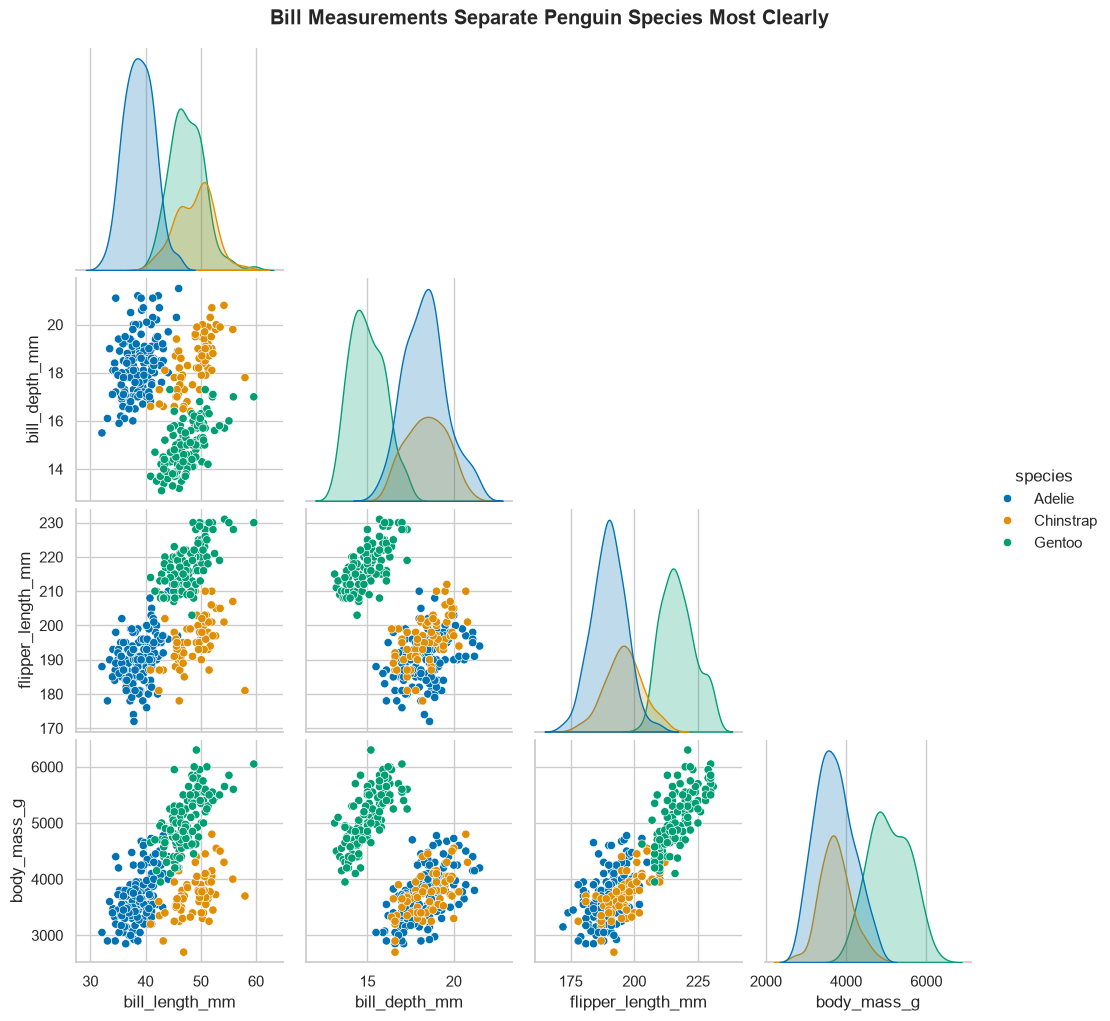

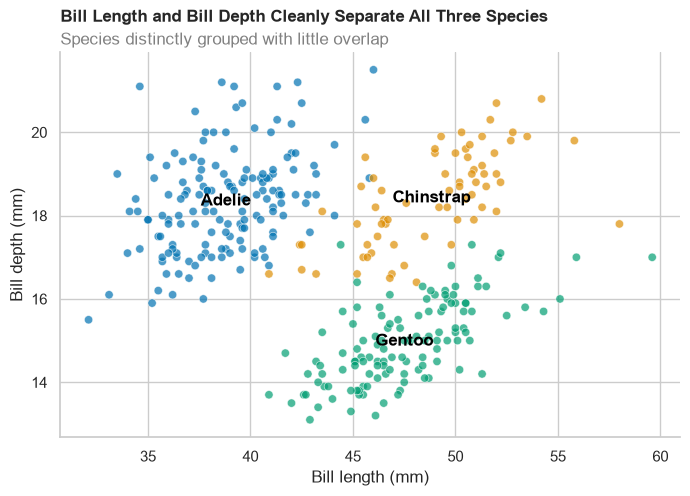

In [12]:
# Your code here
# Pair Plot
g = sns.pairplot(penguins, vars=MEASUREMENTS, hue='species', palette=SPECIES_COLORS, corner=True)
g.figure.suptitle('Bill Measurements Separate Penguin Species Most Clearly', y=1.02, fontweight='bold')
plt.show()

# Polished Single Scatter Plot: Bill Length and Bill Depth

fig, ax = plt.subplots(figsize=(8, 5))

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm',
                hue='species', palette=SPECIES_COLORS, alpha=0.7, legend=False, ax=ax)
means = (penguins.groupby('species')[['bill_length_mm', 'bill_depth_mm']].mean())


for species in SPECIES:
    ax.text(means.loc[species, 'bill_length_mm'], means.loc[species, 'bill_depth_mm'], species, 
            color='black', fontweight='bold', ha='center', va='center')

ax.set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])

finish(ax, 'Bill Length and Bill Depth Cleanly Separate All Three Species',
       subtitle='Species distinctly grouped with little overlap')

plt.savefig(OUT / 'fig7_best_separator.png', dpi=150, bbox_inches='tight')
plt.show()

## 🔥 Challenge (Optional) — A Visual Report on New Data
Pick `titanic.csv` or `pokemon.csv` (copy it into this folder, or use the path `../07-Describing_Data/`). Ask **three** questions, and answer each with one finished chart (finding title, consistent palette, honest scales), saved to `OUT` with a `challenge_` prefix. Write one sentence per chart summarizing the finding.

In [13]:
# Your code here

*Your three findings here.*

## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `06-OutputFiles`. Upload that folder along with this notebook.

In [14]:
for path in sorted(OUT.rglob('*')):
    print(path)

06-OutputFiles\fig1_body_mass_distribution.png
06-OutputFiles\fig2_mass_by_species_sex.png
06-OutputFiles\fig3_species_by_island.png
06-OutputFiles\fig4_correlation_heatmap.png
06-OutputFiles\fig5_bill_paradox.png
06-OutputFiles\fig6_summary.png
06-OutputFiles\fig7_best_separator.png
06-OutputFiles\practice_bill_depth_grid.png


---
### 📝 Summary
This lab turned a numeric report into a visual one:
- **One style for the whole report**: a theme, a category order, a palette dictionary, and a `finish()` helper
- **Distributions** revealed a second group that the skew statistic hid
- **Box + strip** showed both the summary and every penguin
- **Composition** made the island/species confounder visible, with sample sizes
- **Heatmap + paradox figure**: the combined correlation, and why it misleads
- **Every chart was checked against the Module 07 numbers**: charts and statistics work best together

🎓 That's Module 08, and the end of the course's core material. For the **final project**, you'll run this whole cycle (load, clean, describe, visualize, explain) on a dataset of your own.